<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/03_operaciones_geometricas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.3 Operaciones geométricas habituales (resumen)

Resumen del capítulo *Common geometric operations* de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG.

El libro usa datos de Austin. Aquí se usan tus datos: **concejos de Asturias** (`asturias_miteco.gpkg`, polígonos) y **farmacias** (`raw/farmacias_*.geojson`, puntos).

**Idea clave:** cada operación se aplica a toda la columna `geometry` y devuelve una geometría por fila. Si quieres **un único resultado para toda la capa**, primero fusionas las geometrías con `union_all()` o `dissolve()` y luego aplicas la operación.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt

# Folder that contains raw/ and asturias_miteco.gpkg. In Colab, e.g. Path("/content/drive/MyDrive/tfg/datos").
DATA_DIR = Path("/content/drive/MyDrive/tfg/")
CRS_METRES = "EPSG:25830"  # ETRS89 / UTM 30N, units in metres

municipalities = gpd.read_file(DATA_DIR / "miteco_data/out/asturias_miteco.gpkg").to_crs(CRS_METRES)
pharmacies_fp = sorted(DATA_DIR.glob("sitpa_raw_data/farmacias_botiquines__farmacias_*.geojson"))[-1]
pharmacies = gpd.read_file(pharmacies_fp).to_crs(CRS_METRES)

print(len(municipalities), "municipalities |", len(pharmacies), "pharmacies |", municipalities.crs.name)

78 municipalities | 454 pharmacies | ETRS89 / UTM zone 30N


`.to_crs(CRS_METRES)` reproyecta a metros nada más cargar los datos. Se explica en el siguiente capítulo; por ahora basta con saber que **todas las operaciones de este notebook necesitan metros**: con grados, `buffer(5000)` significaría 5000 grados. Si lo olvidas, GeoPandas avisa al calcular centroides o áreas.

## Centroide
El centro geométrico de cada geometría. Devuelve un `Point` por fila. Sirve, por ejemplo, para representar un concejo o un núcleo con un solo punto y medir distancias desde él.

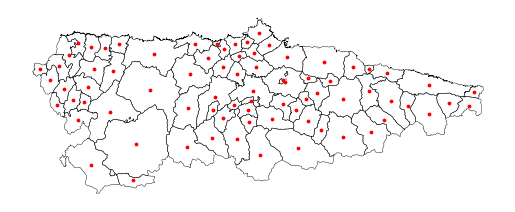

In [ ]:
centroids = municipalities.centroid  # GeoSeries of Points, one per municipality

ax = municipalities.plot(facecolor="none", linewidth=0.3)
centroids.plot(ax=ax, markersize=3, color="red")
ax.set_axis_off()

⚠️ En polígonos con forma irregular, el centroide puede caer **fuera** del polígono. Si necesitas un punto garantizado dentro, usa `representative_point()`.

## Unir geometrías: `union_all()` y `dissolve()`
- `union_all()` fusiona todas las geometrías y devuelve **un objeto shapely**.
- `dissolve()` hace lo mismo pero devuelve un **GeoDataFrame**. Con `by="columna"` fusiona por grupos, como un `groupby` espacial, y con `aggfunc` agrega los atributos (por ejemplo, `"sum"`).

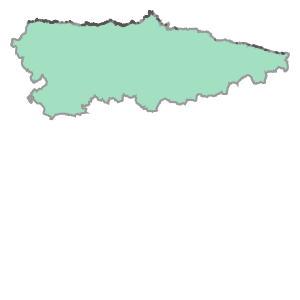

In [ ]:
asturias = municipalities.union_all()  # single (Multi)Polygon: the outline of Asturias
asturias

## Buffer
Crea el polígono de todos los puntos a menos de `d` metros. Aplicado a puntos o polígonos, el resultado siempre es un polígono.

Es la base de preguntas como *¿qué zonas están a menos de 5 km de una farmacia?* (en línea recta, no por carretera).

<StringArray>
['Polygon']
Length: 1, dtype: str


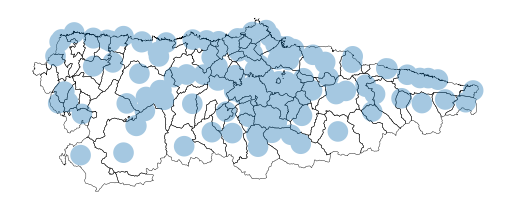

In [ ]:
pharmacy_buffers = pharmacies.buffer(5000)  # one 5 km circle per pharmacy
print(pharmacy_buffers.geom_type.unique())

# Circles overlap. union_all() merges them into the single area "within 5 km of some pharmacy"
covered = pharmacy_buffers.union_all()

ax = municipalities.plot(facecolor="none", linewidth=0.3)
gpd.GeoSeries([covered], crs=CRS_METRES).plot(ax=ax, alpha=0.4)
ax.set_axis_off()

`gpd.GeoSeries([geom], crs=...)` convierte un objeto shapely suelto en algo que se puede dibujar sobre el mapa con el mismo CRS.

## Rectángulo envolvente (*bounding box*)
`total_bounds` devuelve las esquinas `(minx, miny, maxx, maxy)` de toda la capa, y `bounds` las de cada fila. Sirve para filtrar rápido por zona o para recortar datos de otra fuente, como OSM, a la extensión de Asturias.

In [ ]:
print(municipalities.total_bounds)  # metres, EPSG:25830

[ 161252.75673255 4754676.13447296  377649.52545533 4838814.7576704 ]


## Guardar el resultado en el GeoDataFrame
Las operaciones anteriores devuelven una `GeoSeries` nueva; no modifican nada. Para guardar el resultado tienes dos opciones:
1. **Sustituir** la geometría: `gdf["geometry"] = gdf.centroid`. Pierdes la original.
2. **Añadir otra columna** y, si hace falta, activarla con `set_geometry`. GeoPandas usa la geometría **activa** para medir, dibujar y hacer joins.

In [ ]:
municipalities["centroid"] = municipalities.centroid    # second geometry column
points_view = municipalities.set_geometry("centroid")   # new GeoDataFrame whose active geometry is the centroid

print(municipalities.geometry.name, "->", points_view.geometry.name)
print(points_view.geom_type.unique())

geometry -> centroid
<StringArray>
['Point']
Length: 1, dtype: str


Tener varias columnas de geometría es cómodo, pero es fácil equivocarse de columna activa. Usa nombres claros. Además, al guardar en GeoPackage solo se admite una columna de geometría, así que elimina las demás antes de escribir.

## Lo que se ha omitido del capítulo
- `envelope`, `minimum_rotated_rectangle()`, `minimum_bounding_circle()`: otras envolventes. No hacen falta en el TFG.
- `convex_hull` y `concave_hull(ratio=...)`: el contorno de un conjunto de puntos. Podrían servir para dibujar la extensión de un núcleo, pero no están previstos.
- `simplify(tolerance)`: reduce vértices para dibujar más rápido. La tolerancia va en unidades del CRS.
- `dissolve(method="coverage")`: algoritmo más rápido para polígonos que no se solapan.

Documentación: https://geopandas.org/en/stable/docs/user_guide/geometric_manipulations.html